# Import the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.colors as mcolors
import xarray as xr
import xskillscore as xs
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from shapely.geometry import Point
from shapely.ops import unary_union
from shapely.prepared import prep
import dill

# Define the chosen month, the lead time and the start/end of the year

In [2]:
month = "JUL"
lead_time = 1
year_start = '1994'
year_end = '2016'

# Import the output of the CNN (file pickle)

In [3]:
with open('cnn_atl3.pkl', 'rb') as file:
    results_per_leadtime_testing = dill.load(file)

This object is a dictionary composed of the ATL3 prediction from the CNN for each lead time (from 0 to 5 months) and for each month (from April to September). In this exercise we are using only the ATL3 prediction during July at 1 month lead time.

In [4]:
# Extract from the dictionary only the July month ATL3 prediction at 1-month lead time
cnn_atl3_pred_july_1lead = results_per_leadtime_testing[lead_time][month]['ensemble_prediction'].sel(time=slice(year_start,year_end))

# Import 5 European C3S seasonal forecasting systems (file pickle)

This file pickle contains the SST and TPR data of the multi-model (MM) of the 5 European seasonal forecasting systems from C3S for July at lead time of 1 month. The SST and TPR data have been preprocessed: the ATL3 index and the anomaly of TPR. The object is a dictionary.

In [5]:
with open('c3s_mm_jul_lead1.pkl', 'rb') as file:
    mm_dic = dill.load(file)

## ATL3 prediction

In [6]:
# Extract from the dictionary only the July month ATL3 prediction at 1-month lead time for each member of the C3S ensemble
mm_atl3_pred_july_1lead = mm_dic[f'{month}, lead {lead_time} (atl3)']['atl3 index members'].assign_coords(time=mm_dic[f'{month}, lead {lead_time} (atl3)']['atl3 index members'].time.dt.year)

## Total precipitation rate

In [8]:
# Extract from the dictionary only the July month TPR anomaly at 1-month lead time for each member of the C3S ensemble
mm_anomaly_tpr_pred_july_1lead = mm_dic[f'{month}, lead time {lead_time} (tp WA)']['anomaly members'].assign_coords(time=mm_dic[f'{month}, lead time {lead_time} (tp WA)']['anomaly members'].time.dt.year)

# Import the observational datasets used as references (file pickle)

## Total Precipitation Rate [mm/day]

The objects of the file pickle are dictionaries for each observational TPR dataset, containing TPR anomaly and climatology

In [9]:
with open('era5_gpcp_chirps_tpr.pkl', 'rb') as file:
    era5_dic = dill.load(file)
    gpcp_dic = dill.load(file)
    chirps_dic = dill.load(file)

In [10]:
# Extract from the dictionary only the July month TPR anomaly
chirps_tpr_anomaly_july = chirps_dic[f'{month} (tpr)']['anomaly'].sel(time=slice(year_start,year_end))
gpcp_tpr_anomaly_july = gpcp_dic[f'{month} (tpr)']['anomaly'].sel(time=slice(year_start,year_end))
era5_tpr_anomaly_july = era5_dic[f'{month} (tpr)']['anomaly'].sel(time=slice(year_start,year_end))

In [11]:
# Extract from the dictionary only the July month TPR climatology
chirps_tpr_clim_july = chirps_dic[f'{month} (tpr)']['climatology']
gpcp_tpr_clim_july = gpcp_dic[f'{month} (tpr)']['climatology']
era5_tpr_clim_july = era5_dic[f'{month} (tpr)']['climatology']

## ATL3 index

The object of the file pickle is a dictionary containing ATL3 index

In [12]:
with open('oras5_atl3_jul.pkl', 'rb') as file:    
    oras5_dic = dill.load(file)

In [13]:
# Extract from the dictionary only the July month ATL3 index
oras5_atl3_july = oras5_dic['sst'][f'{month} (atl3)']['atl3 index'].sel(time=slice(year_start,year_end))

# Define the time/latitude/longitude coordinates and the number of members of the C3S ensemble

In [14]:
time_coord = mm_anomaly_tpr_pred_july_1lead.time
n_members = mm_anomaly_tpr_pred_july_1lead.number
lat_coord = mm_anomaly_tpr_pred_july_1lead.lat
lon_coord = mm_anomaly_tpr_pred_july_1lead.lon

# Coordinates for West Africa region

In [15]:
# Geographical limits of the West Africa domain, necessary for the plots
lat_regions = [30,-2]
lon_regions = [-17,27]
xticks_wa = np.arange(-10,30,10)
yticks_wa = np.arange(0,40,10)

In [16]:
# Upload countries boundaries
shpfilename = shpreader.natural_earth(resolution='50m',
                                        category='cultural',
                                        name='admin_0_countries')
reader = shpreader.Reader(shpfilename)
countries = list(reader.records())

# List of West Africa countries
wa_countries = ["Mauritania","Mali","Niger","Nigeria","Benin","Togo","Ghana","Côte d'Ivoire","Liberia","Sierra Leone","Burkina Faso",
    "Guinea","Guinea-Bissau","The Gambia","Senegal","Chad","Cameroon","Central African Republic", "Congo", "Gabon","Equatorial Guinea"
]

# Extract geometries of the West Africa countries
geometries_wa = [c.geometry for c in countries if c.attributes['NAME_LONG'] in wa_countries]
combined_polygon_wa = unary_union(geometries_wa)
prepared_poly_wa = prep(combined_polygon_wa)

## Coordinates for Ghana

In [17]:
# Extract the geometry of Ghana from the Natural Earth countries
geometries_ghana = [c.geometry for c in countries if c.attributes['NAME_LONG'] == 'Ghana']
combined_polygon_ghana = unary_union(geometries_ghana)
prepared_poly_ghana = prep(combined_polygon_ghana)

# Functions

In [18]:
# Plot the time series of the ATL3 index for observation, CNN prediction and C3S ensemble prediction
def plot_ts_atl3(n_rows,n_cols,fig_size,obs_tc,cnn_tc,hind_tc,title_suptitle):
    
    fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=fig_size)

    ax.plot(obs_tc.time.values,obs_tc,label='ORAS5',ls='--', linewidth=0.8,color='C0')
    ax.plot(cnn_tc.time.values,cnn_tc,color='C1',label='CNN 1-month lead time',ls='-', linewidth=0.8)
    ax.plot(hind_tc.time.values,hind_tc.mean(dim='number'),color='C2',label='C3S MMM 1-month lead time',ls='-', linewidth=0.8) #For the C3S the multi-model mean is considered

    # Label and axis
    ax.set_xticks(ticks=hind_tc.time[::2])
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='both', labelsize=7)
    ax.set_ylabel('ATL3 index', fontsize=10)
    ax.set_xlabel('Year', fontsize=10)
    ax.legend(loc='best')
    fig.suptitle(title_suptitle, fontsize=16, y=0.95)

    return fig

In [19]:
# Compute the Anomaly Correlation Coefficient (ACC) between the observed variable and the forecasted variable for each possible subsample size
def compute_acc_teleconnection_subsampling(subsample_dataset,obs):
    
    acc = []
    for m in range(len(subsample_dataset.number)): #cycle on the number of total elements
        acc.append(xs.pearson_r(subsample_dataset[:,:(m+1)].mean(dim=('number')),obs,dim='time'))
    return acc

In [20]:
# Compute the mean Anomaly Correlation Coefficient (ACC) between observed and forecasted variables, using random permutations of ensemble members.
# If spatial_mean=True the ACC is averaged over lat/lon inside each iteration, so the 95% interval refers to the area-averaged ACC. This refers to the ACC tp-tp computation and not to the ACC tc-tc computation.
def compute_acc_random_subsampling(hind,obs,iterations,spatial_mean=False):
    
    acc_final = []
    for i in range(iterations): #run n times for random
        #Number of members
        n_members = len(hind.number)
        
        #Extract random members and create a new hindcast ordered based on the randomly selected members
        rand_perm_list = []
        for t in range(len(hind.time)): #For each year
            #Random permutation of member indices
            random_members = np.random.permutation(n_members)
            #Reorder ensemble members for this time step
            members_t = []
            for m in range(n_members):
                member = hind[random_members[m],t] #for each element
                members_t.append(member) #append the element

            # Stack members and assign proper coords
            member_stack = xr.concat(members_t, dim='number')
            member_stack = member_stack.assign_coords(number=('number', np.arange(n_members)))
            member_stack = member_stack.expand_dims(time=[hind.time[t]])

            rand_perm_list.append(member_stack)
        #Concatenate across time
        random_concat_time = xr.concat(rand_perm_list, dim='time') 
        
        #Compute ACC for progressively larger ensemble sizes
        acc = []
        for m in range(n_members):
            acc_m = xs.pearson_r(random_concat_time[:,:(m+1)].mean(dim=('number')),obs, dim='time')
            if spatial_mean: #average the ACC over the area before computing the percentiles
                acc_m = acc_m.mean(dim=('lat','lon'))
            acc.append(acc_m)
        #Concatenate over the 'number' dimension
        acc_concat_m = xr.concat(acc, dim='number') 

        acc_final.append(acc_concat_m)
    #Concatenate over all the iterations and take the mean
    acc_concat = xr.concat(acc_final, dim='iteration')
    acc_random = acc_concat.mean(dim='iteration')

    # Confidence level at the 95%
    acc_low  = acc_concat.quantile(0.025, dim='iteration')
    acc_high = acc_concat.quantile(0.975, dim='iteration')

    return acc_random, acc_low, acc_high

In [21]:
# Plot of the ACC for each subsample obtained from teleconnection-based and random subsampling methods.
# Plot of the ACC for each subsample between observed teleconnection index and CNN ensemble prediction. (Only if computing ACC tc-tc)
def plot_acc_each_sub_size(n_rows,n_cols,fig_size,acc_sub,acc_random_sub,acc_random_low,acc_random_high,obs,ensemble_prediction,yticks,title_string):

    fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=fig_size)

    number_members = len(acc_sub) #Full ensemble size
    condition = all(dim in acc_sub[0].dims for dim in ('lat','lon')) #to distinguish between ACC tp-tp and ACC tc-tc

    #Define the values on the x-axis and y-axis
    if condition: #ACC tp-tp
        y_vals = [acc_sub[k].mean(dim=('lon','lat')).values for k in range(number_members)]
    else: #ACC tc-tc
        y_vals = [acc_sub[k] for k in range(number_members)]
    
    y_vals_random = [acc_random_sub[k] for k in range(number_members)]
    y_vals_random_low = [acc_random_low[k] for k in range(number_members)]
    y_vals_random_high = [acc_random_high[k] for k in range(number_members)]
    x_vals = np.arange(1, number_members + 1)

    #Plot the data
    ax.plot(x_vals, y_vals, color='blue', marker='', markersize=4, linestyle='-',label = 'teleconnection subsampling')
    ax.plot(x_vals, y_vals_random, color='black', marker='', markersize=4, linestyle='-.',label = 'random subsampling')
    ax.fill_between(x_vals, y_vals_random_low, y_vals_random_high, alpha=0.2, color='grey',label='95% CL random subsampling',linestyle='--')
    if not condition: #only for ACC tc-tc
        ax.axhline(y=np.round(xs.pearson_r(obs,ensemble_prediction,dim='time'),3).values,color='red',linestyle='--',label='CNN prediction')
    ax.set_xlabel('Number of members', fontsize=12)
    ylabel = 'ACC'
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_xticks(x_vals[::9])
    ax.tick_params(axis='x', labelsize=7)
    ax.set_yticks(yticks)
    ax.tick_params(axis='y', labelsize=7)
    ax.legend(loc='best')

    fig.suptitle(title_string, fontsize=16, y=0.98)
    return fig

In [22]:
# Build a discrete colormap with one colour per interval between consecutive levels.
def define_cmap_levels_norm_colormap(name_colormap_string,number_intervals,min_interval,max_interval,spacing_interval):
    cmap = plt.get_cmap(name_colormap_string, number_intervals)
    colors = cmap(np.linspace(0, 1, number_intervals)) # Extract color array

    if name_colormap_string == 'BrBG_r': # 'BrBG_r' has both negative and positive values
        # Replace the middle color (near 0) with white
        midpoint = int(number_intervals/2)  # Middle of number_intervals
        colors[midpoint] = [1, 1, 1, 1]
        colors[midpoint-1] = [1, 1, 1, 1]

    # Create a new colormap with the modified colors
    custom_cmap = mcolors.ListedColormap(colors)

    # Define custom boundaries
    cmap_bounds = np.arange(min_interval,max_interval,spacing_interval) #OBS: in np.arange max_interval is excluded from the interval, so it must be greater than what we want it, as we define it
    norm = mcolors.BoundaryNorm(cmap_bounds, custom_cmap.N)
    
    return custom_cmap, cmap_bounds, norm

In [23]:
# Mask the data with a polygon (keep only the grid points inside it).
# Crop to a lat/lon box before masking (lat_regions, lon_regions). This is for the West Africa region.
# And/or select only the north (lat >= lat_split) or south (lat < lat_split) part. This is only for Ghana.
def mask_polygon(data, prepared_poly,lat_regions=None, lon_regions=None,lat_split=None,part=None):
    data_sel = data
    if lat_regions is not None and lon_regions is not None:
        data_sel = data.sel(lat=slice(lat_regions[0], lat_regions[1]),
                         lon=slice(lon_regions[0], lon_regions[1]))
    lat2d, lon2d = np.meshgrid(data_sel.lat, data_sel.lon, indexing='ij')
    mask_inside = np.array([[prepared_poly.covers(Point(lon2d[y, x], lat2d[y, x]))
                              for x in range(lon2d.shape[1])]
                             for y in range(lat2d.shape[0])])
    data_masked = data_sel.where(mask_inside)

    # North and South Ghana
    if part == 'south':
        data_masked = data_masked.where(data_masked.lat < lat_split, drop=True)
    elif part == 'north':
        data_masked = data_masked.where(data_masked.lat >= lat_split, drop=True)

    return data_masked

In [24]:
# Plot the ACC difference between the hybrid precipitation prediction (subsample of a specific size) and the full C3S ensemble prediction of precipitation
def plot_acc_difference(n_rows,n_cols,fig_size,h_space,w_space,list_acc_tp_tp,
                         list_name_obs, n_members_subsample,
                         custom_cmap, cmap_bounds, norm,
                         xticks, yticks, title_suptitle,
                         precip_threshold,tc_levels,
                         list_climatology=None, list_acc_tc_tp=None,
                        ):
    
    fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=fig_size,
                            subplot_kw={"projection": ccrs.PlateCarree()})
    fig.subplots_adjust(hspace=h_space,wspace=w_space)

    for j in range(n_cols):

        # Masks for the climatology and the ACC tc-tp
        mask_clim_poly = mask_polygon(list_climatology[j], prepared_poly_wa, lat_regions, lon_regions) \
            if list_climatology[j] is not None else None
        mask_tc_poly = mask_polygon(list_acc_tc_tp[j],prepared_poly_wa, lat_regions, lon_regions) \
            if list_acc_tc_tp[j] is not None else None

        # Mask for precipitation threshold
        precip_mask = mask_clim_poly > precip_threshold if mask_clim_poly is not None else None

    
        data_to_plot = list_acc_tp_tp[j][n_members_subsample - 1] - list_acc_tp_tp[j][-1]

        mask = mask_polygon(data_to_plot, prepared_poly_wa, lat_regions, lon_regions)
        if precip_mask is not None:
            mask = mask.where(precip_mask)

        plot= ax[j].contourf(mask.lon, mask.lat, mask,
                                     cmap=custom_cmap, levels=cmap_bounds,
                                     norm=norm, extend='both')

        if mask_tc_poly is not None:
            mt = mask_tc_poly.where(precip_mask) if precip_mask is not None else mask_tc_poly
            cs_tc = ax[j].contour(mt.lon, mt.lat, mt,
                                   levels=tc_levels, colors='black',
                                   linewidths=0.8, linestyles='--')
            ax[j].clabel(cs_tc, inline=True, fontsize=5, fmt='%.1f')

        if mask_clim_poly is not None:
            dry_mask = (mask_clim_poly <= precip_threshold).astype(int)
            dry_mask_sel = dry_mask.sel(lat=mask.lat, lon=mask.lon)
            with plt.rc_context({'hatch.linewidth': 0.3}):
                ax[j].contourf(dry_mask_sel.lon, dry_mask_sel.lat, dry_mask_sel,
                                levels=[0.5, 1.5], colors='none',
                                hatches=['////'], zorder=5)

        # Map features
        ax[j].coastlines(linestyle='--', edgecolor='gray', linewidth=0.3)
        ax[j].add_feature(cfeature.BORDERS, linestyle='--', edgecolor='gray', linewidth=0.3)
        extent = [-18, 28, -4, 28]
        ax[j].set_extent(extent, crs=ccrs.PlateCarree())
        ax[j].add_geometries([combined_polygon_wa], crs=ccrs.PlateCarree(),
                              facecolor='none', edgecolor='black', linewidth=0.8, zorder=10)

        ax[j].set_xticks(xticks)
        ax[j].set_yticks(yticks)
        ax[j].tick_params(axis='both', labelsize=7)
        lon_formatter = LongitudeFormatter(zero_direction_label=False)
        lat_formatter = LatitudeFormatter()
        ax[j].xaxis.set_major_formatter(lon_formatter)
        ax[j].yaxis.set_major_formatter(lat_formatter)
        ax[0].set_ylabel('latitude(°N)', fontsize=10)
        ax[j].set_xlabel('longitude(°E)', fontsize=10)

        ax[j].set_title(list_name_obs[j])

    # Colorbars
    fig.colorbar(plot, ax=ax, orientation='horizontal', shrink=0.5, aspect=50).set_label('ACC', fontsize=10)

    # Legend
    legend_handles = []
    if mask_tc_poly is not None:
        legend_handles.append(Line2D([0], [0], color='black', lw=0.8, ls='--',
                                      label='ACC ATL3 vs TPR'))
    if precip_mask is not None:
        legend_handles.append(Patch(facecolor='none', edgecolor='gray',hatch='/////',
                                     label=f'TPR climatology ≤ {precip_threshold} mm/day'))
    if legend_handles:
        fig.legend(handles=legend_handles, loc='lower center', ncol=len(legend_handles),
                   bbox_to_anchor=(0.5, 0.8), frameon=True, fontsize=9)

    fig.suptitle(title_suptitle, fontsize=16, y=0.95)
    return fig

# Plot the time series of Atlantic Niño

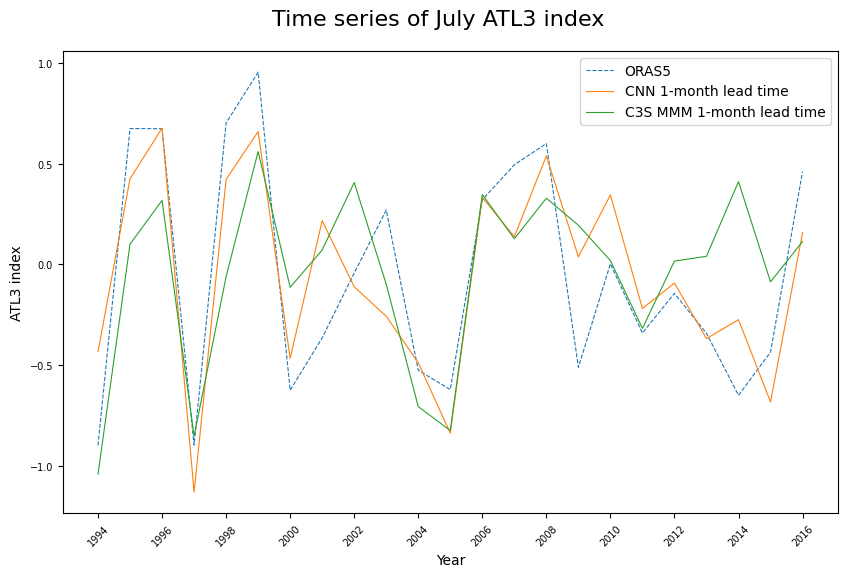

In [25]:
ts_atl3 = plot_ts_atl3(1,1,(10,6),oras5_atl3_july,cnn_atl3_pred_july_1lead,mm_atl3_pred_july_1lead,'Time series of July ATL3 index')

# Teleconnection subsampling method

In [26]:
# Compute the Euclidean distance (absolute difference, since the ATL3 index is a scalar) between the ATL3 Index prediction from the C3S ensemble and the CNN 
euclidean_distance = abs(mm_atl3_pred_july_1lead - cnn_atl3_pred_july_1lead)

In [27]:
# Select the members with the smallest Euclidean distance and sort them in ascending order
selected_members_di = []
for t in range(len(time_coord)): #For each year
    sort_members = euclidean_distance.isel(time=t).argsort()
    
    top_n_list = []
    for n in range(len(n_members)): #For each member
        top_n = sort_members[:(n+1)] #Select the first n members
        top_n_list.append(top_n)
    selected_members_di.append(top_n_list)

In [28]:
# Reorder the MM ensemble members in ascending order of their Euclidean distance, such that member 0 corresponds to the smallest distance.
#ATL3
subsampling_atl3_list = []
for t in range(len(time_coord)): #For each year
    member_indices = selected_members_di[t][-1]  # All the members selected for this time step. The last element contains all the members sorted
    members_t = mm_atl3_pred_july_1lead.sel(number=member_indices, time=time_coord[t])
    subsampling_atl3_list.append(members_t)
subsampling_atl3 = xr.DataArray(subsampling_atl3_list, dims=('time', 'number'), coords={'time': time_coord, 'number': n_members.values})

#TPR --> same members ordered by smaller euclidean distance but for the TPR
subsampling_wa_july_list = []
for t in range(len(time_coord)): # For each year
    member_indices = selected_members_di[t][-1]
    #print(member_indices)
    members_t = mm_anomaly_tpr_pred_july_1lead.sel(number=member_indices, time=time_coord[t])
    subsampling_wa_july_list.append(members_t)
subsampling_wa_july = xr.DataArray(subsampling_wa_july_list, dims=('time', 'number','lat','lon'), coords={'time': time_coord, 'number': mm_anomaly_tpr_pred_july_1lead.number.values, 'lat': lat_coord, 'lon': lon_coord})

## Compute the ACC between the ATL3 index prediction from the C3S ensemble and ORAS5 for each possible subsample size (from 1 member to up to the full ensemble of 148 members)

### Teleconnection subsampling method

In [29]:
# ACC between the C3S ensemble and ORAS5 for each possible subsample size by using the member order from the teleconnection subsampling method
acc_tc_tc = compute_acc_teleconnection_subsampling(subsampling_atl3,oras5_atl3_july)

### Random subsampling method
Choose the number of iterations for the random subsampling

In [30]:
# ACC between the C3S ensemble and ORAS5 for each possible subsample size by using a random order of the members
# CHOOSE the number of iterations for the random subsampling (e.g., 10,20,100,1000,...)
acc_tc_tc_random, acc_tc_tc_random_low, acc_tc_tc_random_high = compute_acc_random_subsampling(mm_atl3_pred_july_1lead,oras5_atl3_july,20,spatial_mean=False)

### Plot the results of the ACC computation for the teleconnection subsampling and the random subsampling

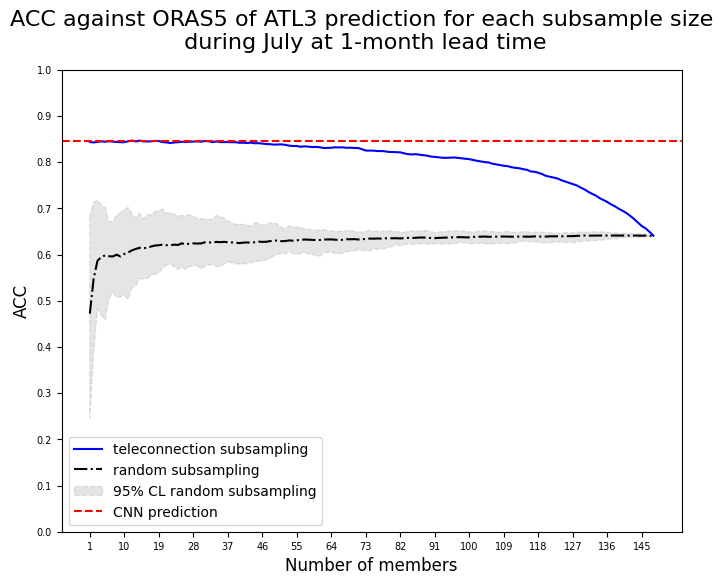

In [31]:
plot_acc_tc_tc = plot_acc_each_sub_size(1,1,(8,6),acc_tc_tc,acc_tc_tc_random,acc_tc_tc_random_low,acc_tc_tc_random_high,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(0.,1.05,0.1),'ACC against ORAS5 of ATL3 prediction for each subsample size\n during July at 1-month lead time')

### Compute the ACC between the TPR prediction from the C3S ensemble and GPCP/CHIRPS/ERA5 for each possible subsample size (from 1 member to up to the full ensemble of 148 members).

In [32]:
#ERA5
acc_tp_tp_era5 = compute_acc_teleconnection_subsampling(subsampling_wa_july,era5_tpr_anomaly_july)
#GPCP
acc_tp_tp_gpcp = compute_acc_teleconnection_subsampling(subsampling_wa_july,gpcp_tpr_anomaly_july)
#CHIRPS
acc_tp_tp_chirps = compute_acc_teleconnection_subsampling(subsampling_wa_july,chirps_tpr_anomaly_july)

/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den
/home/sarab/myenv/lib/python3.12/s

### Focus on North and South Ghana, with boundary at 8°N latitude

#### South Ghana

In [33]:
subsampling_ghana_south = mask_polygon(subsampling_wa_july, prepared_poly_ghana, lat_split=8, part='south')
era5_ghana_south = mask_polygon(era5_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='south')
gpcp_ghana_south = mask_polygon(gpcp_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='south')
chirps_ghana_south = mask_polygon(chirps_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='south')
mm_anomaly_tpr_ghana_south = mask_polygon(mm_anomaly_tpr_pred_july_1lead, prepared_poly_ghana, lat_split=8, part='south')

In [34]:
#ERA5
acc_tp_tp_ghana_south_era5 = compute_acc_teleconnection_subsampling(subsampling_ghana_south,era5_ghana_south)
#GPCP
acc_tp_tp_ghana_south_gpcp = compute_acc_teleconnection_subsampling(subsampling_ghana_south,gpcp_ghana_south)
#CHIRPS
acc_tp_tp_ghana_south_chirps = compute_acc_teleconnection_subsampling(subsampling_ghana_south,chirps_ghana_south)

##### Random subsampling method South Ghana

In [35]:
#ERA5
acc_tp_tp_ghana_south_random_era5,acc_tp_tp_ghana_south_random_low_era5,acc_tp_tp_ghana_south_random_high_era5 = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_south,era5_ghana_south,20,spatial_mean=True)
#GPCP
acc_tp_tp_ghana_south_random_gpcp,acc_tp_tp_ghana_south_random_low_gpcp,acc_tp_tp_ghana_south_random_high_gpcp = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_south,gpcp_ghana_south,20,spatial_mean=True)
#CHIRPS
acc_tp_tp_ghana_south_random_chirps,acc_tp_tp_ghana_south_random_low_chirps,acc_tp_tp_ghana_south_random_high_chirps = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_south,chirps_ghana_south,20,spatial_mean=True)

##### Plot the results for ERA5/GPCP/CHIRPS for South Ghana

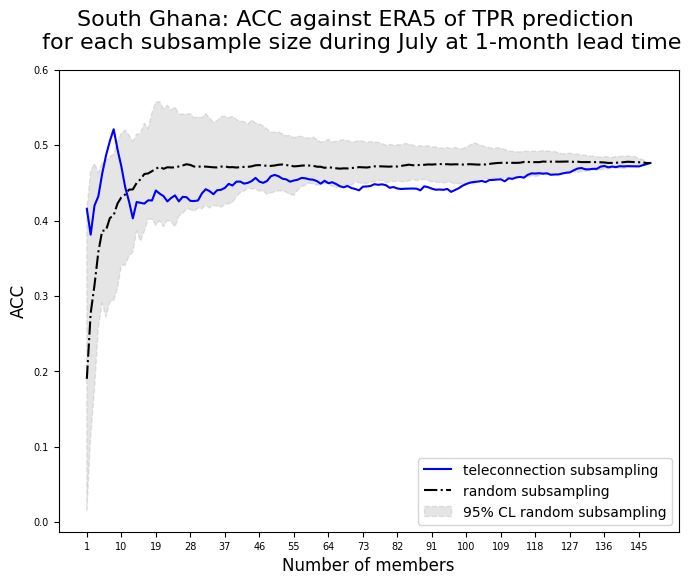

In [36]:
plot_acc_tp_tp_ghana_south_era5 = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_south_era5,acc_tp_tp_ghana_south_random_era5,acc_tp_tp_ghana_south_random_low_era5,acc_tp_tp_ghana_south_random_high_era5,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(0.,0.65,0.1),'South Ghana: ACC against ERA5 of TPR prediction \n for each subsample size during July at 1-month lead time')

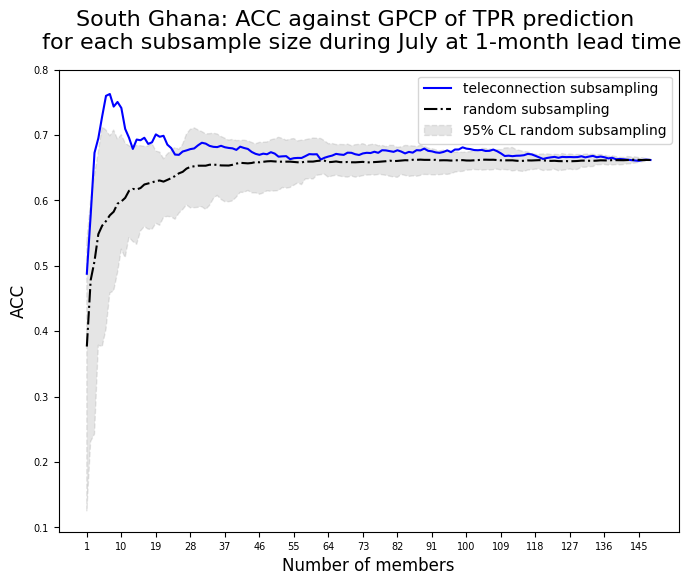

In [37]:
plot_acc_tp_tp_ghana_south_gpcp = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_south_gpcp,acc_tp_tp_ghana_south_random_gpcp,acc_tp_tp_ghana_south_random_low_gpcp,acc_tp_tp_ghana_south_random_high_gpcp,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(0.1,0.85,0.1),'South Ghana: ACC against GPCP of TPR prediction \n for each subsample size during July at 1-month lead time')

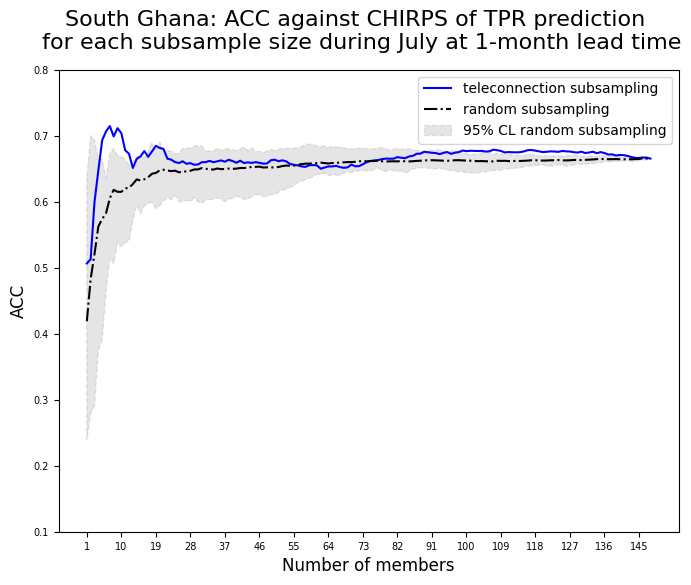

In [38]:
plot_acc_tp_tp_ghana_south_chirps = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_south_chirps,acc_tp_tp_ghana_south_random_chirps,acc_tp_tp_ghana_south_random_low_chirps,acc_tp_tp_ghana_south_random_high_chirps,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(0.1,0.85,0.1),'South Ghana: ACC against CHIRPS of TPR prediction \n for each subsample size during July at 1-month lead time')

#### North Ghana

In [39]:
subsampling_ghana_north = mask_polygon(subsampling_wa_july, prepared_poly_ghana, lat_split=8, part='north')
era5_ghana_north = mask_polygon(era5_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='north')
gpcp_ghana_north = mask_polygon(gpcp_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='north')
chirps_ghana_north = mask_polygon(chirps_tpr_anomaly_july, prepared_poly_ghana, lat_split=8, part='north')
mm_anomaly_tpr_ghana_north = mask_polygon(mm_anomaly_tpr_pred_july_1lead, prepared_poly_ghana, lat_split=8, part='north')

In [40]:
#ERA5
acc_tp_tp_ghana_north_era5 = compute_acc_teleconnection_subsampling(subsampling_ghana_north,era5_ghana_north)
#GPCP
acc_tp_tp_ghana_north_gpcp = compute_acc_teleconnection_subsampling(subsampling_ghana_north,gpcp_ghana_north)
#CHIRPS
acc_tp_tp_ghana_north_chirps = compute_acc_teleconnection_subsampling(subsampling_ghana_north,chirps_ghana_north)

##### Random subsampling method for North Ghana

In [41]:
#ERA5
acc_tp_tp_ghana_north_random_era5,acc_tp_tp_ghana_north_random_low_era5,acc_tp_tp_ghana_north_random_high_era5 = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_north,era5_ghana_north,20,spatial_mean=True)
#GPCP
acc_tp_tp_ghana_north_random_gpcp,acc_tp_tp_ghana_north_random_low_gpcp,acc_tp_tp_ghana_north_random_high_gpcp = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_north,gpcp_ghana_north,20,spatial_mean=True)
#CHIRPS
acc_tp_tp_ghana_north_random_chirps,acc_tp_tp_ghana_north_random_low_chirps,acc_tp_tp_ghana_north_random_high_chirps = compute_acc_random_subsampling(mm_anomaly_tpr_ghana_north,chirps_ghana_north,20,spatial_mean=True)

##### Plot the results for ERA5/GPCP/CHIRPS for North Ghana

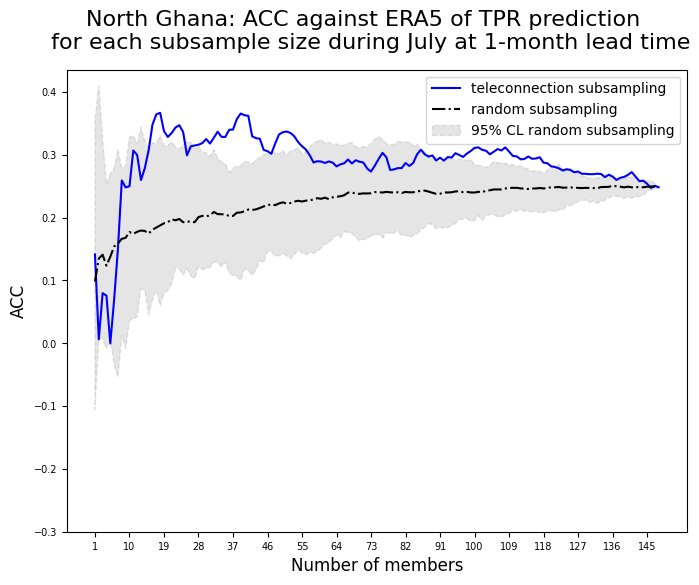

In [42]:
plot_acc_tp_tp_ghana_north_era5 = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_north_era5,acc_tp_tp_ghana_north_random_era5,acc_tp_tp_ghana_north_random_low_era5,acc_tp_tp_ghana_north_random_high_era5,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(-0.3,0.45,0.1),'North Ghana: ACC against ERA5 of TPR prediction \n for each subsample size during July at 1-month lead time')

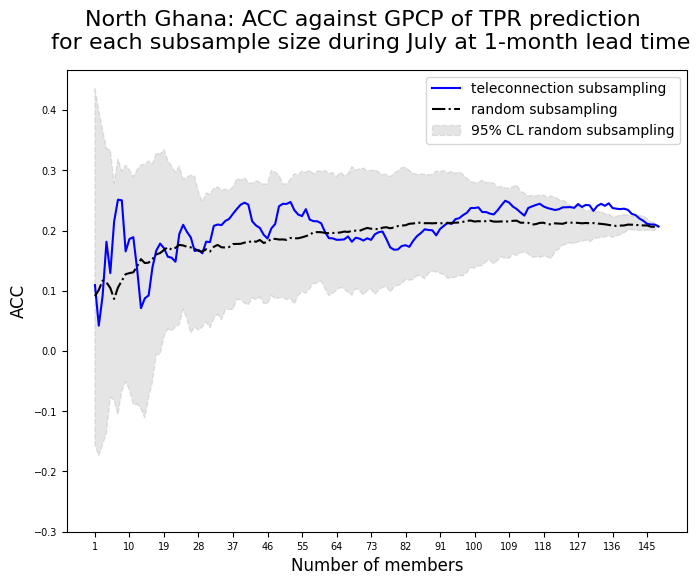

In [43]:
plot_acc_tp_tp_ghana_north_gpcp = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_north_gpcp,acc_tp_tp_ghana_north_random_gpcp,acc_tp_tp_ghana_north_random_low_gpcp,acc_tp_tp_ghana_north_random_high_gpcp,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(-0.3,0.45,0.1),'North Ghana: ACC against GPCP of TPR prediction \n for each subsample size during July at 1-month lead time')

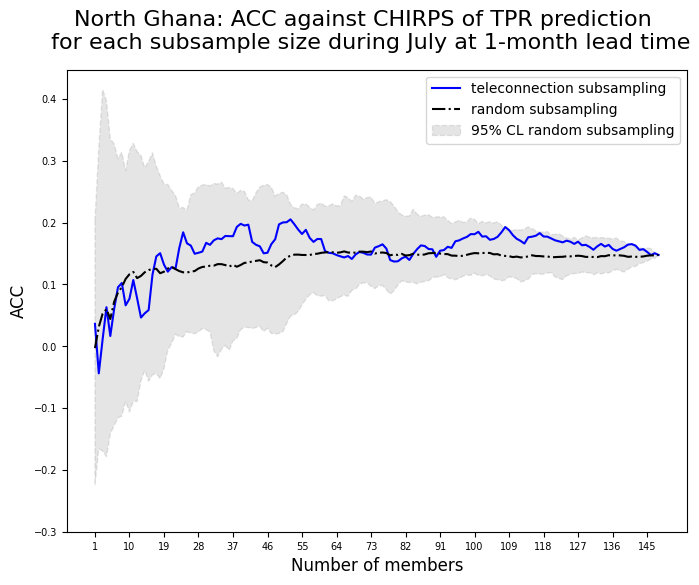

In [44]:
plot_acc_tp_tp_ghana_north_chirps = plot_acc_each_sub_size(1,1,(8,6),acc_tp_tp_ghana_north_chirps,acc_tp_tp_ghana_north_random_chirps,acc_tp_tp_ghana_north_random_low_chirps,acc_tp_tp_ghana_north_random_high_chirps,oras5_atl3_july,cnn_atl3_pred_july_1lead,np.arange(-0.3,0.45,0.1),'North Ghana: ACC against CHIRPS of TPR prediction \n for each subsample size during July at 1-month lead time')

# Choose the size of the subsample size to produce the hybrid precipitation forecast for the entire West Africa
The choice is based on the ACC tc-tc plot

In [45]:
# Insert the number (e.g., 52,71,...)
size = 52

# Prototype of a Hybrid Precipitation Forecast for the entire West Africa

## Compute the ACC between the observed ATL3 index and TPR

In [46]:
# Compute the ACC for each observational dataset as reference
list_obs_tpr_anomaly_july = [era5_tpr_anomaly_july,gpcp_tpr_anomaly_july,chirps_tpr_anomaly_july]
list_obs_tpr_clim_july = [era5_tpr_clim_july,gpcp_tpr_clim_july,chirps_tpr_clim_july]

july_corr = []
for i in range(len(list_obs_tpr_anomaly_july)):
    july_corr.append(xs.pearson_r(oras5_atl3_july,list_obs_tpr_anomaly_july[i],dim='time'))

/home/sarab/myenv/lib/python3.12/site-packages/xskillscore/core/np_deterministic.py:314: RuntimeWarning: invalid value encountered in divide
  r = r_num / r_den


## Plot the difference in ACC between the hybrid precipitation prediction and the full ensemble of C3S

In [47]:
# Define lists for the three TPR observational datasets
list_acc_tp_tp = [acc_tp_tp_era5,acc_tp_tp_gpcp,acc_tp_tp_chirps]
list_name_obs_tp = ['ERA5','GPCP','CHIRPS']

In [48]:
#Define the colormap for the plot
custom_cmap_brbg, cmap_bounds_brbg, norm_brbg = define_cmap_levels_norm_colormap('BrBG_r',13,-0.3,0.35,0.05)

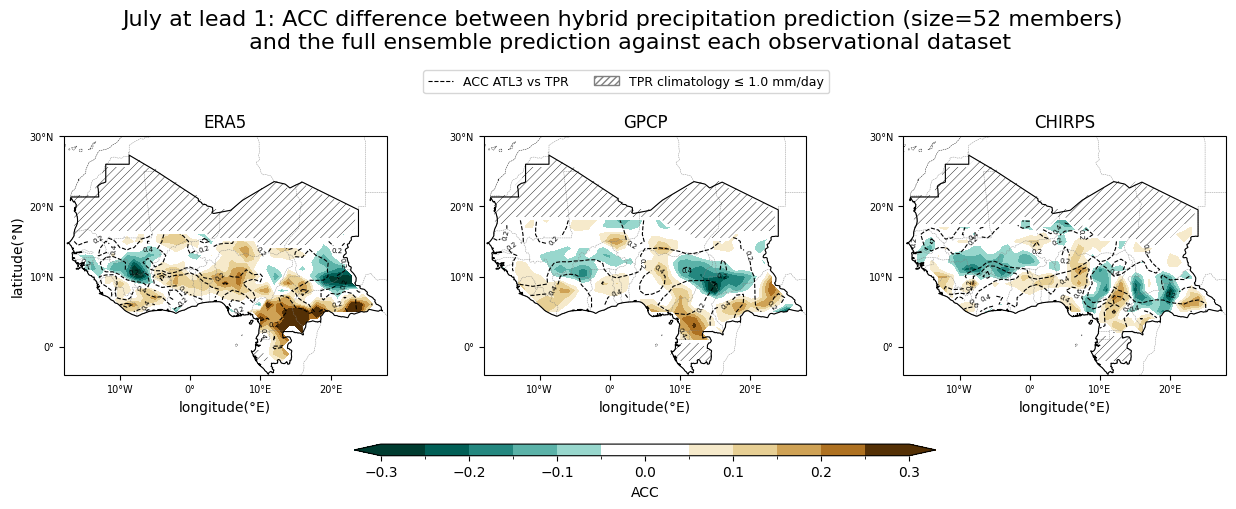

In [49]:
plot_difference = plot_acc_difference(1,3,(15,6),0.3,0.3,list_acc_tp_tp,list_name_obs_tp,size,
                         custom_cmap_brbg, cmap_bounds_brbg, norm_brbg,
                         xticks_wa, yticks_wa, f'July at lead 1: ACC difference between hybrid precipitation prediction (size={size} members) \n and the full ensemble prediction against each observational dataset',
                         1.0,[0.2, 0.4, 0.6, 0.8],
                        list_climatology=list_obs_tpr_clim_july, list_acc_tc_tp=july_corr
                        )

# References

Bachèlery, Marie-Lou, et al. "Predicting Atlantic and Benguela Niño events with deep learning." Science Advances 11.14 (2025): eads5185. DOI: 10.1126/sciadv.ads5185

Johnson SJ, Stockdale TN, Ferranti L, Balmaseda MA, Molteni F, Magnusson L, et al. SEAS5: the new ECMWF seasonal forecast system. Geoscientific Model Development. 2019;12(3):1087-117. doi:10.5194/gmd-12-1087-2019.

Gualdi S, Borrelli A, Cantelli A, Davoli G, del Mar Chavesmontero M, Masina S, et al. The new CMCC operational seasonal prediction system. Bologna, Italy: Euro-Mediterranean Center on Climate Change (CMCC), Climate Simulation and Prediction Division; 2020. doi:10.25424/CMCC/SPS3.5.

Williams KD, Copsey D, Blockley EW, Bodas-Salcedo A, Calvert D, Comer R, et al. The Met Office Global Coupled Model 3.0 and 3.1 (GC3.0 and GC3.1) Configurations. Journal of Advances in Modeling Earth Systems. 2018;10(2):357-80. doi:10.1002/2017MS001115.

Fröhlich K, Dobrynin M, Isensee K, Gessner C, Paxian A, Pohlmann H, et al. The German climate forecast system: GCFS. Journal of Advances in Modeling Earth Systems. 2021;13(2):e2020MS002101. doi:10.1029/2020MS002101.

Batté L, Dorel L, Ardilouze C, Guérémy J. Documentation of the METEO-FRANCE seasonal forecasting system 8. Copernicus Climate Change Service Tech Rep. 2021.

Funk C, Peterson P, Landsfeld M, Pedreros D, Verdin J, Shukla S, et al. The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes. Scientific data. 2015;2(1):1-21. doi:10.1038/sdata.2015.66.

Adler RF, Sapiano MR, Huffman GJ, Wang JJ, Gu G, Bolvin D, et al. The Global Precipitation Climatology Project (GPCP) monthly analysis (new version 2.3) and a review of 2017 global precipitation. Atmosphere. 2018;9(4):138. doi:10.3390/atmos9040138.

Hersbach H, Bell B, Berrisford P, Hirahara S, Hor´anyi A, Muñoz-Sabater J, et al. The ERA5 global reanalysis. Quarterly journal of the royal meteorological society. 2020;146(730):1999-2049. doi:10.1002/qj.3803

Zuo, Hao, et al. "The ECMWF operational ensemble reanalysis–analysis system for ocean and sea ice: a description of the system and assessment." Ocean science 15.3 (2019): 779-808. https://doi.org/10.5194/os-15-779-2019